# Estudo 06 – H5: a previsibilidade muda entre mercado calmo e agitado?

Hipótese H5 das [notas](../NOTAS.md). Em períodos turbulentos, há quem espere **exageros e reversões** (pânico, liquidez escassa); outros esperam **tendências** (notícias grandes absorvidas aos poucos). Também há um motivo econômico para olhar o regime: quando os movimentos são maiores, um custo fixo em pontos pesa **menos** (ρ\* = c/M cai, Estudo 01).

Perguntas:

1. Dá para classificar o regime **antes** do pregão, sem olhar o futuro?
2. A autocorrelação dos candles muda entre os regimes?
3. A diferença entre calmo e agitado é real? (**bootstrap em blocos**, ferramenta nova)
4. O custo pesa menos no regime agitado?
5. O candidato C2 (momentum no fechamento) depende do regime?

**Dados:** WIN, só até 31/12/2024.

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, sys
from pathlib import Path
from scipy import stats

PASTA = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "tt1_comum.py").exists())
sys.path.append(str(PASTA)); sys.path.append(str(PASTA / "frentes" / "estatistico"))
import tt1_comum as t
import custos as cu

rng = np.random.default_rng(5)
AZUL, LARANJA, VERDE, CINZA = "#2a78d6", "#eb6834", "#1baf7a", "#8a8984"
COR_REGIME = {"calmo": "#86b6ef", "médio": "#2a78d6", "agitado": "#184f95"}
ORDEM = ["calmo", "médio", "agitado"]
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e6e5e0", "grid.linewidth": 0.6,
                     "axes.edgecolor": "#a3a29c", "axes.labelcolor": "#52514e",
                     "xtick.color": "#52514e", "ytick.color": "#52514e", "lines.linewidth": 1.6})
CUSTOS = {nome: p["custo_pts"] for nome, p in cu.CENARIOS.items()}

win = t.carregar(f"{PASTA}/dados/WINN_M1/WIN$N_M1.csv")
win = win[win.index < "2025-01-01"]

def corr_z(x, y):
    x, y = np.asarray(x) - np.mean(x), np.asarray(y) - np.mean(y)
    return (x * y).sum() / np.sqrt((x * x).sum() * (y * y).sum()), (x * y).sum() / np.sqrt((x * x * y * y).sum())

def holm(pvals, alfa=0.05):
    p = np.asarray(pvals); ordem = np.argsort(p); m = len(p); ok = np.zeros(m, bool)
    for i, j in enumerate(ordem):
        if p[j] <= alfa / (m - i):
            ok[j] = True
        else:
            break
    return ok

## 1. Classificando o regime sem olhar o futuro

**Volatilidade realizada do dia:** raiz da soma dos quadrados dos retornos de 1 min do pregão (sem o gap noturno). Mede "quanto o preço sacudiu" naquele dia.

**Regime do dia D**, decidido **antes** de D começar:

1. pegar a volatilidade realizada de **ontem** (D − 1);
2. comparar com os **60 pregões anteriores** a ontem;
3. classificar: acima do percentil 67 → **agitado**; abaixo do 33 → **calmo**; entre os dois → **médio**.

**Por que não dividir o período todo em terços?** Porque os limites dos terços usariam a volatilidade de dias **futuros**. Num estudo descritivo isso parece inofensivo, mas é vazamento de informação: uma regra assim não poderia ser aplicada em tempo real.

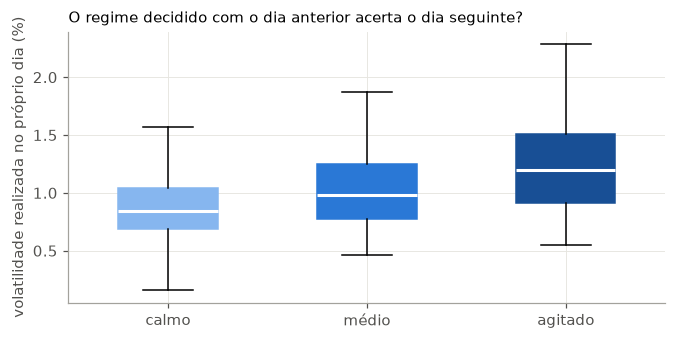

{'calmo': 328, 'médio': 270, 'agitado': 295}
volatilidade média no próprio dia, por regime: {'calmo': 0.89, 'médio': 1.03, 'agitado': 1.25}


In [2]:
dia = pd.Series(win.index.normalize(), index=win.index)
r1 = np.log(win.close).diff(); r1[dia != dia.shift()] = np.nan
vol_dia = np.sqrt((r1 ** 2).groupby(dia).sum()) * 100              # volatilidade realizada do dia (%)

ontem = vol_dia.shift(1)
q33 = ontem.rolling(60, min_periods=40).quantile(1 / 3).shift(1)    # limites calculados só com o passado de ontem
q67 = ontem.rolling(60, min_periods=40).quantile(2 / 3).shift(1)
regime = pd.Series(np.where(ontem > q67, "agitado", np.where(ontem < q33, "calmo", "médio")), index=vol_dia.index)
regime[q33.isna()] = np.nan

fig, ax = plt.subplots(figsize=(7, 3.2))
dados = [vol_dia[regime == r] for r in ORDEM]
bp = ax.boxplot(dados, tick_labels=ORDEM, widths=0.5, showfliers=False, patch_artist=True,
                medianprops=dict(color="white", lw=2))
for patch, r in zip(bp["boxes"], ORDEM):
    patch.set_facecolor(COR_REGIME[r]); patch.set_edgecolor(COR_REGIME[r])
ax.set_ylabel("volatilidade realizada no próprio dia (%)")
ax.set_title("O regime decidido com o dia anterior acerta o dia seguinte?", loc="left", fontsize=10); plt.show()
print(regime.value_counts().reindex(ORDEM).to_dict())
print("volatilidade média no próprio dia, por regime:", vol_dia.groupby(regime).mean().reindex(ORDEM).round(2).to_dict())

**Leitura:** o regime decidido com a volatilidade de **ontem** separa bem a volatilidade de **hoje** (≈ 0,9% nos dias "calmos" contra ≈ 1,25% nos "agitados"). A volatilidade **persiste** de um dia para o outro. Isso já é uma forma de previsibilidade (da volatilidade, não da direção) e é o tema da H6.

## 2. A autocorrelação muda entre os regimes?

ρ₁ entre candles seguidos (5, 15 e 60 min), separado pelo regime do dia. São 9 testes.

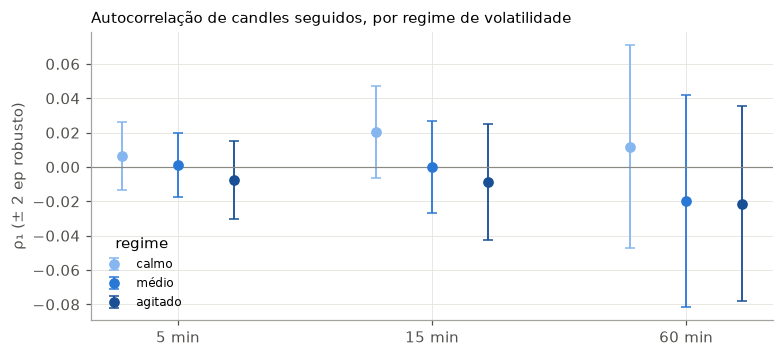

,candle_min,regime,n,rho1,z_robusto,mov_medio_pts,custo_equilibrio_pts,rho_nec_base,p,signif_holm
0,5,calmo,35418,0.0062,0.6209,72.2576,0.4447,0.1038,0.5347,False
1,5,médio,29271,0.0014,0.1541,82.1385,0.1180,0.0913,0.8775,False
2,5,agitado,31791,-0.0073,-0.6455,98.4275,0.7203,0.0762,0.5186,False
3,15,calmo,11479,0.0204,1.5368,124.4551,2.5423,0.0603,0.1244,False
4,15,médio,9488,-0.0000,-0.0019,141.5978,0.0035,0.0530,0.9985,False
5,15,agitado,10305,-0.0088,-0.5235,167.4309,1.4758,0.0448,0.6006,False
6,60,calmo,2476,0.0118,0.4007,230.3069,2.7272,0.0326,0.6887,False
7,60,médio,2046,-0.0199,-0.6454,254.6725,5.0629,0.0294,0.5186,False
8,60,agitado,2210,-0.0213,-0.7482,306.9253,6.5438,0.0244,0.4543,False


In [3]:
linhas, bases = [], {}
for k in [5, 15, 60]:
    c = win.resample(f"{k}min").agg({"close": "last"}).dropna()
    d = pd.Series(c.index.normalize(), index=c.index)
    r = np.log(c.close).diff(); r[d != d.shift()] = np.nan
    prox = r.shift(-1); prox[d.shift(-1) != d] = np.nan
    prox_pts = c.close.shift(-1) - c.close
    df = pd.DataFrame({"r": r, "prox": prox, "prox_pts": prox_pts, "dia": d, "regime": regime.reindex(d.values).values}).dropna()
    bases[k] = df
    for g in ORDEM:
        x = df[df.regime == g]
        rho, z = corr_z(x.r, x.prox); M = x.prox_pts.abs().mean()
        linhas.append(dict(candle_min=k, regime=g, n=len(x), rho1=rho, z_robusto=z, ep=rho / z if z else np.nan,
                           mov_medio_pts=M, custo_equilibrio_pts=abs(rho) * M, rho_nec_base=CUSTOS["base"] / M))
tab2 = pd.DataFrame(linhas)
tab2["p"] = 2 * (1 - stats.norm.cdf(tab2.z_robusto.abs()))
tab2["signif_holm"] = holm(tab2.p)

fig, ax = plt.subplots(figsize=(8, 3.4))
for i, g in enumerate(ORDEM):
    d = tab2[tab2.regime == g]; xs = np.arange(3) + (i - 1) * 0.22
    ax.errorbar(xs, d.rho1, yerr=2 * d.ep, fmt="o", color=COR_REGIME[g], ms=6, capsize=3, lw=1.2, label=g)
ax.axhline(0, color=CINZA, lw=0.8); ax.set_xticks(range(3), ["5 min", "15 min", "60 min"])
ax.set_ylabel("ρ₁ (± 2 ep robusto)"); ax.legend(frameon=False, title="regime", fontsize=8)
ax.set_title("Autocorrelação de candles seguidos, por regime de volatilidade", loc="left", fontsize=10); plt.show()
tab2.drop(columns="ep").round(4)

**Leitura:** nenhum dos 9 testes é significativo (todos |z| ≤ 1,5). Há um **padrão nos sinais**: ρ₁ levemente positivo nos dias calmos e levemente negativo nos agitados, nos três tamanhos de candle. Seria coerente com "reversão em mercado turbulento". Mas cada valor está dentro do ruído. A pergunta certa é se a **diferença** entre agitado e calmo é real.

## 3. A diferença é real? O bootstrap em blocos

Queremos o erro-padrão de **ρ(agitado) − ρ(calmo)**. Não há uma fórmula simples para isso com volatilidade variando e candles do mesmo dia dependentes entre si. O **bootstrap** resolve por simulação, usando os próprios dados:

1. sortear, **com reposição**, tantos dias quanto os que temos (alguns dias aparecem duas vezes, outros nenhuma);
2. recalcular a diferença nessa amostra sorteada;
3. repetir 1.000 vezes. O desvio-padrão das 1.000 diferenças é o erro-padrão.

**Por que sortear dias inteiros (blocos) e não candles soltos?** Candles do mesmo dia compartilham a volatilidade e as notícias daquele dia, então não são independentes. Sortear o dia inteiro preserva essa dependência; sortear candles soltos a destruiria e daria um erro-padrão pequeno demais.

In [4]:
def diferenca(S):
    a = S[S.regime == "agitado"][["xy", "xx", "yy"]].sum(); b = S[S.regime == "calmo"][["xy", "xx", "yy"]].sum()
    return a.xy / np.sqrt(a.xx * a.yy) - b.xy / np.sqrt(b.xx * b.yy)

linhas = []
for k, df in bases.items():
    x = df[df.regime.isin(["calmo", "agitado"])].copy()
    x["xy"] = (x.r - x.r.mean()) * (x.prox - x.prox.mean()); x["xx"] = (x.r - x.r.mean()) ** 2; x["yy"] = (x.prox - x.prox.mean()) ** 2
    S = x.groupby(["dia", "regime"])[["xy", "xx", "yy"]].sum().reset_index()      # um bloco por dia
    obs = diferenca(S)
    boot = [diferenca(S.sample(len(S), replace=True, random_state=int(s))) for s in rng.integers(0, 2**31, 1000)]
    linhas.append(dict(candle_min=k, dif_agitado_menos_calmo=obs, ep_bootstrap=np.std(boot), z=obs / np.std(boot)))
pd.DataFrame(linhas).round(4)

,candle_min,dif_agitado_menos_calmo,ep_bootstrap,z
0,5,-0.0135,0.0129,-1.0422
1,15,-0.0292,0.0220,-1.3276
2,60,-0.0332,0.0442,-0.7502


**Leitura:** as diferenças têm o sinal esperado ("mais reversão no agitado"), mas |z| ≤ 1,4. **Não há evidência** de que a previsibilidade mude entre os regimes. O padrão de sinais da Seção 2 é compatível com acaso.

## 4. O custo pesa menos no regime agitado?

Com movimentos maiores, o mesmo ρ renderia mais pontos, e o ρ necessário para pagar o custo (ρ\* = c/M) cai.

In [5]:
piv = tab2.pivot(index="candle_min", columns="regime", values="rho_nec_base")[ORDEM]
piv_m = tab2.pivot(index="candle_min", columns="regime", values="mov_medio_pts")[ORDEM]
piv_abs = tab2.assign(rho_abs=tab2.rho1.abs()).pivot(index="candle_min", columns="regime", values="rho_abs")[ORDEM]
display(pd.concat({"movimento médio (pts)": piv_m, "ρ necessário (base 7,5)": piv, "|ρ₁| medido": piv_abs}, axis=1).round(3))

movimento médio (pts)                   ρ necessário (base 7,5)  \
regime                     calmo    médio  agitado                   calmo   
candle_min                                                                   
5                         72.258   82.138   98.428                   0.104   
15                       124.455  141.598  167.431                   0.060   
60                       230.307  254.673  306.925                   0.033   

                          |ρ₁| medido                 
regime      médio agitado       calmo  médio agitado  
candle_min                                            
5           0.091   0.076       0.006  0.001   0.007  
15          0.053   0.045       0.020  0.000   0.009  
60          0.029   0.024       0.012  0.020   0.021

**Leitura:** no regime agitado os movimentos são ~35% maiores e o ρ necessário cai na mesma proporção (em 60 min, de 0,033 para 0,024). Mas o |ρ₁| medido continua bem abaixo do necessário em todos os casos. A volatilidade alta **baixa a barra**, mas não cria previsibilidade.

## 5. O candidato C2 depende do regime?

O C2 ([notas](../NOTAS.md), Seção 6): seguir o movimento do dia na última meia hora. Aqui só **descrevemos** como ele se comporta em cada regime. **A regra pré-registrada não muda**: mudar depois de ver estes números seria exatamente o ajuste que o pré-registro proíbe. Serve como **teste de robustez**: um efeito real não deveria depender de um detalhe como o regime.

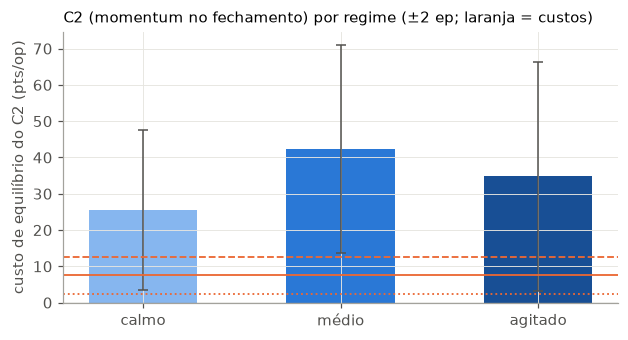

,n,media_pts,ep
regime,,,
calmo,311,25.5,11.0
médio,262,42.5,14.3
agitado,285,34.8,15.8


In [6]:
def vencimentos(anos):
    out = []
    for y in anos:
        for m in [2, 4, 6, 8, 10, 12]:
            d15 = pd.Timestamp(y, m, 15); off = 2 - d15.weekday()
            off = off - 7 if off > 3 else off + 7 if off < -3 else off
            out.append(d15 + pd.Timedelta(days=off))
    return set(out)

venc = vencimentos(range(2020, 2026)); linhas = []
for d_, x in win.groupby(win.index.normalize()):
    t0, fim = x.index[0], x.index[-1]
    if (fim - t0) < pd.Timedelta(hours=8):
        continue
    cl = x.close; a = fim - pd.Timedelta(minutes=30)
    linhas.append(dict(dia=d_, fechamento=cl.iloc[-1], p_fim30=cl[cl.index <= a].iloc[-1]))
Dd = pd.DataFrame(linhas).set_index("dia")
Dd["fech_ontem"] = Dd.fechamento.shift(); Dd["dias"] = Dd.index.to_series().diff().dt.days
Dd = Dd[(Dd.dias <= 4) & ~Dd.index.isin(venc)].copy()
Dd["resultado_pts"] = np.sign(np.log(Dd.p_fim30 / Dd.fech_ontem)) * (Dd.fechamento - Dd.p_fim30)
Dd["regime"] = regime.reindex(Dd.index)
c2 = Dd.dropna().groupby("regime").resultado_pts.agg(n="size", media_pts="mean", ep=lambda v: v.std() / np.sqrt(len(v))).reindex(ORDEM)

fig, ax = plt.subplots(figsize=(6.5, 3.2))
ax.bar(ORDEM, c2.media_pts, color=[COR_REGIME[r] for r in ORDEM], width=0.55)
ax.errorbar(range(3), c2.media_pts, yerr=2 * c2.ep, fmt="none", color="#52514e", capsize=3, lw=1)
for nome, estilo in [("otimista", ":"), ("base", "-"), ("conservador", "--")]:
    ax.axhline(CUSTOS[nome], color=LARANJA, lw=1.2, ls=estilo)
ax.axhline(0, color=CINZA, lw=0.8); ax.set_ylabel("custo de equilíbrio do C2 (pts/op)")
ax.set_title("C2 (momentum no fechamento) por regime (±2 ep; laranja = custos)", loc="left", fontsize=10); plt.show()
c2.round(1)

**Leitura:** o C2 é positivo e acima dos custos nos **três** regimes (+25 a +43 pts). Não depende de o mercado estar calmo ou agitado. Ponto a favor do candidato: a única dependência encontrada até agora é a do horário do pregão (Estudo 04).

## 6. Conclusões de H5

| Pergunta | Resposta |
|---|---|
| Dá para classificar o regime sem olhar o futuro? | Sim. A volatilidade de ontem (comparada com os 60 pregões anteriores) separa bem a de hoje: ela **persiste** |
| A autocorrelação muda entre regimes? | Não: 9 testes, todos |z| ≤ 1,5. Há um padrão de sinais (reversão no agitado), mas a diferença agitado − calmo tem |z| ≤ 1,4 no bootstrap |
| O custo pesa menos no agitado? | Sim: o ρ necessário cai ~25%. Mas o |ρ₁| medido fica abaixo dele em qualquer regime |
| O C2 depende do regime? | Não: positivo e acima dos custos nos três. Ponto de robustez a favor do candidato |

**Lições gerais:**

1. **Classificações e limites só com o passado.** Terços do período inteiro usam o futuro, mesmo num estudo descritivo.
2. **Bootstrap em blocos:** quando não há fórmula para o erro-padrão, reamostrar os dados, sorteando **blocos** que preservem a dependência (aqui, dias inteiros).
3. **Testar a diferença, não comparar significâncias.** "Significativo num grupo e não no outro" não prova que os grupos diferem; é preciso testar a diferença diretamente.

Nenhum candidato novo.